# Model 1: a simple text classifier

**Goal:** read a clinical note and predict its medical specialty (12 classes).

**The idea in one sentence:** count which words appear in each note (TF-IDF, lecture T5), then let a linear classifier learn which words point to which specialty.

Steps:
1. Load the data
2. Remove the "cheating" keyword
3. Combine the text fields into one text
4. Split into train / test
5. Build the model: TF-IDF + linear SVM
6. Evaluate it
7. Look at some mistakes
8. Predict the official test set

## 1. Load the data
`train_clean.csv` is the cleaned training file produced by `Data_Profile.ipynb`. Each row has a label (`medical_specialty`) and four text fields.

In [1]:
import pandas as pd

train = pd.read_csv("train_clean.csv", sep=";", dtype=str, keep_default_na=False)
print(train.shape)
train.head(3)

(2669, 5)


,medical_specialty,description,sample_name,transcription,keywords
0,Cardiovascular-Pulmonary,"Chest pain, possible syncopal spells. She ha...",Chest Pain - Cardiac Consult,"REASON FOR REFERRAL: Chest pain, possible syn...","cardiovascular / pulmonary, chest pain, syncop..."
1,Cardiovascular-Pulmonary,"The patient is 14 months old, comes in with a ...",Difficulty Breathing - ER Visit,"HISTORY: The patient is 14 months old, comes ...",
2,Cardiovascular-Pulmonary,"Fiberoptic bronchoscopy, diagnostic. Hemopty...",Fiberoptic Bronchoscopy - 1,"PREOPERATIVE DIAGNOSIS:1. Hemoptysis.,2. His...","cardiovascular / pulmonary, hemoptysis, lung c..."


## 2. Remove the "cheating" keyword
In every row that has keywords, the **first keyword is the label itself** (e.g. `cardiovascular / pulmonary, chest pain, ...`). If we keep it, the model just reads the answer instead of learning from the clinical text. So we drop the first keyword.

In [2]:
def drop_first_keyword(keywords):
    parts = keywords.split(",")
    return ",".join(parts[1:])          # everything except the first keyword

print("before:", train.keywords[0][:80])
train["keywords"] = train["keywords"].apply(drop_first_keyword)
print("after: ", train.keywords[0][:80])

before: cardiovascular / pulmonary, chest pain, syncopal, echocardiogram, ekg, cardiac e
after:   chest pain, syncopal, echocardiogram, ekg, cardiac etiology, syncopal spells, r


## 3. Combine the text fields
The model needs **one text per row**, so we glue the four fields together.

In [3]:
def combine(df):
    return df["description"] + " " + df["sample_name"] + " " + df["keywords"] + " " + df["transcription"]

X = combine(train)            # input: the text
y = train["medical_specialty"]  # output: the label
print(X[0][:300])

 Chest pain, possible syncopal spells.  She has been having multiple cardiovascular complaints including chest pains, which feel like cramps and sometimes like a dull ache, which will last all day long.  Chest Pain - Cardiac Consult   chest pain, syncopal, echocardiogram, ekg, cardiac etiology, sync


## 4. Split into train and test (lecture T2)
The official test file has no labels, so we can't score ourselves on it. We keep **20%** of the training data aside as our own test set. The model never sees it while training.

* `stratify=y` keeps the same class proportions in both parts (important: Dermatology has only 25 rows).
* `random_state=42` makes the split identical every time you run it (reproducibility).

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(len(X_train), "training rows,", len(X_test), "test rows")

2135 training rows, 534 test rows


## 5. The model: TF-IDF + linear SVM
The model is a **pipeline** with two steps.

**Step 1: `TfidfVectorizer` turns each text into a vector of numbers.**
* It lowercases the text, splits it into words, and gives every word a score: **TF-IDF = how often the word is in this note × how rare the word is across all notes.** Words like *the* appear everywhere, so they get a low score. Words like *colonoscopy* are rare, so they get a high one.
* `sublinear_tf=True`: a word repeated 20 times counts more than once, but not 20× more.
* `min_df=2`: ignore words that appear in only one note (mostly typos).

**Step 2: `LinearSVC` (linear Support Vector Machine) learns one weight per word for each specialty.** To classify a note, it adds up the weights of its words and picks the specialty with the highest total.
* `class_weight="balanced"`: Surgery has 893 rows and Dermatology only 25. Without this, the model mostly predicts the big classes. "Balanced" makes mistakes on small classes cost more.
* `C=0.3`: controls how closely the model fits the training data. Smaller values give a simpler model that is less likely to overfit.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

model = make_pipeline(
    TfidfVectorizer(sublinear_tf=True, min_df=2),
    LinearSVC(C=0.3, class_weight="balanced"),
)
model.fit(X_train, y_train)
print("number of words the model knows:", len(model[0].vocabulary_))

number of words the model knows: 13857


## 6. Evaluate (lecture T4)
* **Accuracy** = fraction of correct predictions. *Project gate 1: must be above 49%.*
* **F1 per class** = balance of precision (when I say X, am I right?) and recall (did I find all the X's?). *Project gate 2: no class below 25%.*

In [6]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

pred = model.predict(X_test)
print("accuracy:     ", round(accuracy_score(y_test, pred), 3))
print("worst class F1:", round(f1_score(y_test, pred, average=None).min(), 3))
print()
print(classification_report(y_test, pred, digits=3, zero_division=0))

accuracy:      0.442
worst class F1: 0.203

                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.455     0.403     0.427        62
             Dermatology      0.750     0.600     0.667         5
        Gastroenterology      0.431     0.641     0.515        39
        General Medicine      0.576     0.905     0.704        42
               Neurology      0.375     0.324     0.348        37
            Neurosurgery      0.250     0.438     0.318        16
   Obstetrics-Gynecology      0.462     0.667     0.545        27
           Ophthalmology      0.483     0.933     0.636        15
              Orthopedic      0.342     0.433     0.382        60
   Psychiatry-Psychology      0.750     0.750     0.750         8
               Radiology      0.229     0.182     0.203        44
                 Surgery      0.519     0.302     0.382       179

                accuracy                          0.442       534
               macro avg      

### Confusion matrix (rows = true label, columns = predicted)

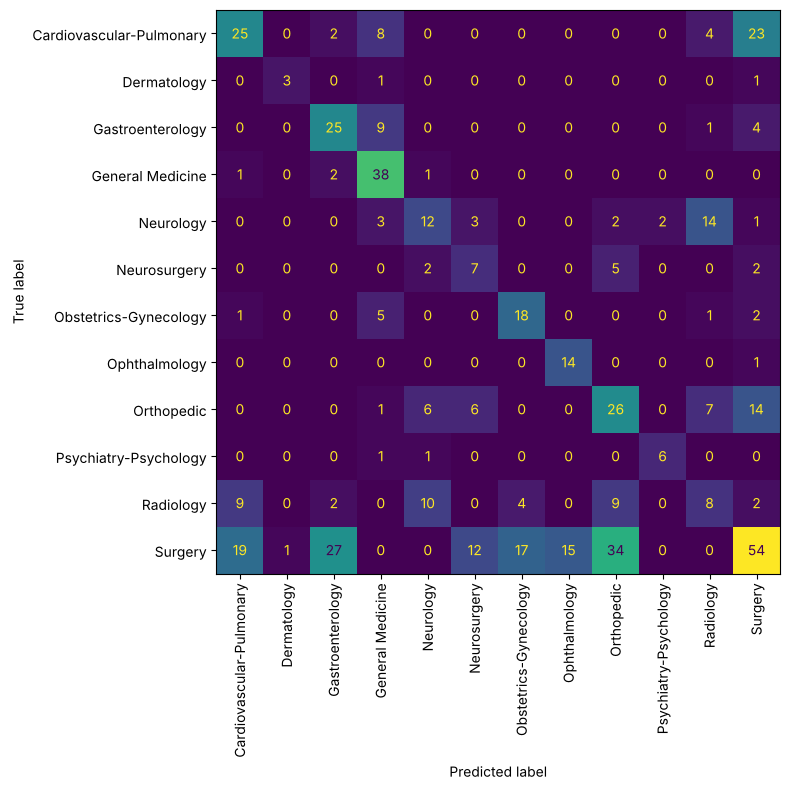

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout(); plt.show()

## 7. Look at some mistakes


In [8]:
results = pd.DataFrame({"text": X_test.str[:150], "true": y_test, "predicted": pred})
mistakes = results[results.true != results.predicted]
print(len(mistakes), "mistakes out of", len(results))
mistakes.head(8)

298 mistakes out of 534


,text,true,predicted
2379,Coronary artery bypass grafting times three u...,Surgery,Cardiovascular-Pulmonary
1710,CT of chest with contrast. Abnormal chest x-...,Radiology,Cardiovascular-Pulmonary
1731,Ultrasound BPP - Advanced maternal age and hy...,Radiology,Obstetrics-Gynecology
2170,"Left heart catheterization, bilateral selecti...",Surgery,Cardiovascular-Pulmonary
1824,Bilateral Crawford subtalar arthrodesis with ...,Surgery,Orthopedic
1982,Common description of colonoscopy Colonoscopy...,Surgery,Gastroenterology
2629,Revision right total knee arthroplasty. Righ...,Surgery,Orthopedic
2038,The patient had undergone mitral valve repair...,Surgery,Cardiovascular-Pulmonary


In [9]:
# How many mistakes are "the same note filed under another specialty"?
same_note_labels = train.groupby("transcription")["medical_specialty"].agg(set)
notes = train.loc[mistakes.index, "transcription"]
other_label = [p in same_note_labels[t] for t, p in zip(notes, mistakes.predicted)]
print(f"{sum(other_label)} of {len(mistakes)} mistakes predict a label that the SAME note has elsewhere in the data")

228 of 298 mistakes predict a label that the SAME note has elsewhere in the data


## 8. Predict the official test set
`test_no_labels.csv` has **no header row** (the first line is already a record), so we read it with `header=None` and give the columns names ourselves. We then apply **exactly the same steps** as for training (drop the first keyword, combine the fields).

Before predicting, we retrain the model on **all** the labelled data (more data → slightly better model).

In [10]:
test = pd.read_csv("test_no_labels.csv", sep=";", header=None, dtype=str, keep_default_na=False,
                   names=["description", "sample_name", "transcription", "keywords"])
test["keywords"] = test["keywords"].apply(drop_first_keyword)

model.fit(X, y)                                   # retrain on all labelled data
test_pred = model.predict(combine(test))

with open("results_model1.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(test_pred) + "\n")
print(len(test), "test rows ->", len(test_pred), "predictions saved")
pd.Series(test_pred).value_counts()

398 test rows -> 398 predictions saved


Surgery                     74
Cardiovascular-Pulmonary    50
Orthopedic                  44
Gastroenterology            42
General Medicine            38
Neurology                   33
Obstetrics-Gynecology       31
Neurosurgery                29
Radiology                   23
Ophthalmology               19
Psychiatry-Psychology       11
Dermatology                  4
Name: count, dtype: int64

## Summary
| | |
|---|---|
| Input | description + sample name + keywords (first one removed) + transcription |
| Features | TF-IDF word scores |
| Classifier | linear SVM, class-balanced, C = 0.3 |
| Our test score | see section 6 (≈ 0.44 accuracy) |
| Main weakness | the same note appears with different labels |

